In [3]:
import cudf
import cuml
import cupy as cp
import matplotlib.pyplot as plt
import seaborn as sns
from cuml.model_selection import train_test_split
from cuml.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from cuml.decomposition import PCA
from cuml.cluster import DBSCAN
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score, accuracy_score
from sklearn.model_selection import ParameterGrid
import numpy as np
import warnings
import kagglehub
warnings.filterwarnings('ignore')
from joblib import Parallel, delayed

In [4]:
cuml.set_global_output_type('cupy')

In [5]:
def draw_confusion_matrix(cm, title='Confusion Matrix'):
    plt.figure(figsize=(6, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=['Not Fraud', 'Fraud'], yticklabels=['Not Fraud', 'Fraud'])
    plt.title(title)
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.show()

In [6]:
def print_confusion_matrix(cm, title):
    print(f"{title}:")
    print("         Predicted")
    print("         Not Fraud  Fraud")
    print("Actual")
    print(f"Not Fraud  {cm[0,0]:6d}  {cm[0,1]:6d}")
    print(f"Fraud      {cm[1,0]:6d}  {cm[1,1]:6d}")

In [7]:
path = kagglehub.dataset_download("ealaxi/banksim1")
print("Path to dataset files:", path)

Path to dataset files: /kaggle/input/banksim1


In [8]:
data = cudf.read_csv(path + '/bs140513_032310.csv')

In [9]:
data = data.drop(['zipcodeOri', 'zipMerchant'], axis=1)
data['customer'] = data['customer'].str[1:-1]
data['age'] = data['age'].str[1:-1]
data['gender'] = data['gender'].str[1:-1]
data['merchant'] = data['merchant'].str[1:-1]
data['category'] = data['category'].str.replace('es_', '')
data = data[data['gender'] != 'U']
data['age'] = data['age'].replace('U', '7')
data['age'] = data['age'].astype('float32')

In [10]:
data['amount'] = data['amount'].astype('float32')
data['amount_thresh'] = cudf.Series('>3000', index=data.index)
data.loc[data['amount'] <= 500, 'amount_thresh'] = '0-500'
data.loc[(data['amount'] > 500) & (data['amount'] <= 1000), 'amount_thresh'] = '500-1000'
data.loc[(data['amount'] > 1000) & (data['amount'] <= 1500), 'amount_thresh'] = '1000-1500'
data.loc[(data['amount'] > 1500) & (data['amount'] <= 2000), 'amount_thresh'] = '1500-2000'
data.loc[(data['amount'] > 2000) & (data['amount'] <= 2500), 'amount_thresh'] = '2000-2500'
data.loc[(data['amount'] > 2500) & (data['amount'] <= 3000), 'amount_thresh'] = '2500-3000'

In [11]:
customer = data.groupby('customer').size().reset_index(name='customer_total_trans')
customer['customer_ID'] = cp.arange(1, len(customer) + 1)

merchant = data.groupby('merchant').size().reset_index(name='merchant_total_trans')
merchant['merchant_ID'] = cp.arange(1, len(merchant) + 1)

category = data.groupby('category').size().reset_index(name='category_total_trans')
category['category_ID'] = cp.arange(1, len(category) + 1)

amount_thresh = data.groupby('amount_thresh').size().reset_index(name='amount_thresh_total_trans')
amount_thresh['amount_thresh_ID'] = cp.arange(1, len(amount_thresh) + 1)

In [12]:
data = data.merge(customer, on='customer').merge(merchant, on='merchant')
data = data.drop(['customer', 'merchant'], axis=1)
data = data.merge(category, on='category').merge(amount_thresh, on='amount_thresh')
data['category'] = data['category_ID']
data['amount_thresh'] = data['amount_thresh_ID']
data = data.drop(['category_ID', 'amount_thresh_ID'], axis=1)

age = data.groupby('age').size().reset_index(name='age_total_trans')
gender = data.groupby('gender').size().reset_index(name='gender_total_trans')
data = data.merge(age, on='age').merge(gender, on='gender')

In [13]:
total_freq = len(data)
data['merchant_total_trans'] = (data['merchant_total_trans'] / total_freq * 100).round(5)
data['category_total_trans'] = (data['category_total_trans'] / total_freq * 100).round(5)
data['amount_thresh_total_trans'] = (data['amount_thresh_total_trans'] / total_freq * 100).round(5)
data['age_total_trans'] = (data['age_total_trans'] / total_freq * 100).round(5)
data['gender_total_trans'] = (data['gender_total_trans'] / total_freq * 100).round(5)

data = data.drop('step', axis=1)
data = data[['fraud'] + [col for col in data.columns if col != 'fraud']]

In [15]:
ohe = OneHotEncoder(sparse=True, handle_unknown='ignore')
ohe_cols = ['age', 'gender', 'category', 'amount_thresh']
ohe_data = ohe.fit_transform(data[ohe_cols])
ohe_feature_names = ohe.get_feature_names(ohe_cols)
# Convert sparse matrix to dense CuPy array before creating DataFrame
ohe_data = cudf.DataFrame(ohe_data.toarray(), columns=ohe_feature_names)
data = cudf.concat([data.drop(ohe_cols, axis=1), ohe_data], axis=1)

In [19]:
le = LabelEncoder()
data['fraud'] = le.fit_transform(data['fraud'])

print("Data dimensions:", data.shape)

Data dimensions: (594128, 43)


In [20]:
pca_cols = ['age_0.0', 'age_1.0', 'age_2.0', 'age_3.0', 'age_4.0', 'age_5.0', 'age_6.0', 'age_7.0',
            'gender_E', 'gender_F', 'gender_M',
            'category_1', 'category_2', 'category_3', 'category_4', 'category_5', 'category_6', 'category_7',
            'category_8', 'category_9', 'category_10', 'category_11', 'category_12', 'category_13', 'category_14',
            'amount', 'amount_thresh_1', 'amount_thresh_2', 'amount_thresh_3', 'amount_thresh_4', 'amount_thresh_5',
            'amount_thresh_6', 'amount_thresh_7']
scaler = StandardScaler()
scaled_data_big = scaler.fit_transform(data[pca_cols])
pca = PCA(n_components=2)
pca_data = pca.fit_transform(scaled_data_big)
pca_df = cudf.DataFrame(pca_data, columns=['PC1', 'PC2'])
pca_df['fraud'] = data['fraud']

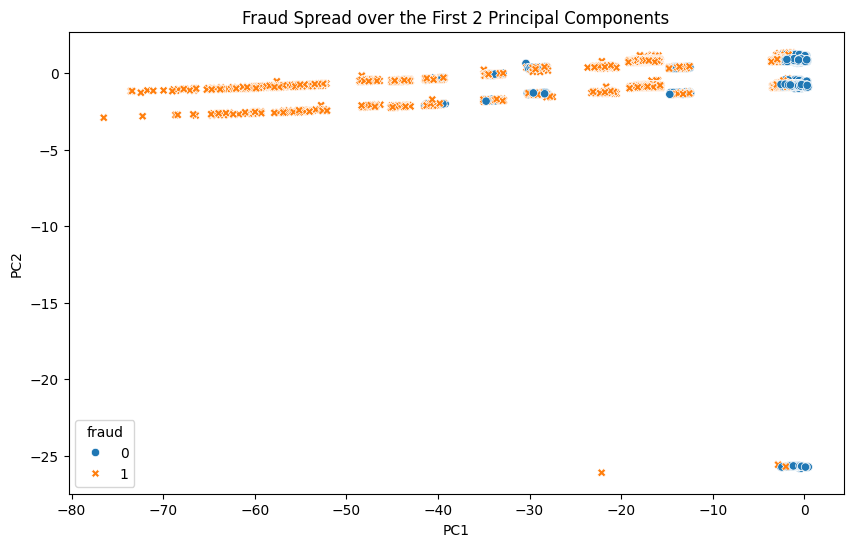

Explained variance ratio: [0.09855887 0.0609752 ]


In [21]:
pca_df_np = pca_df.to_pandas()
plt.figure(figsize=(10, 6))
sns.scatterplot(x='PC1', y='PC2', hue='fraud', style='fraud', data=pca_df_np)
plt.title('Fraud Spread over the First 2 Principal Components')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.show()

print("Explained variance ratio:", cp.asnumpy(pca.explained_variance_ratio_))

In [22]:
X = data.drop('fraud', axis=1)
y = data['fraud']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=123, stratify=y)

In [92]:
sample_frac = 0.5  # 10% of the data
X_sample = X_train.sample(frac=sample_frac, random_state=42)
y_sample = y_train.loc[X_sample.index]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_sample)

In [85]:
# X_sample = X_train.copy()
# y_sample = y_train.copy()
# scaler = StandardScaler()
# X_scaled = scaler.fit_transform(X_sample)

In [86]:
param_grid = {
    'eps': [1.6, 1.65, 1.7, 1.75, 1.8],  # Test near best-performing eps
    'min_samples': [2, 3, 4],             # Test adjacent min_samples
    'fraud_threshold': [0.05, 0.10]       # Test lower thresholds
}

In [87]:
best_f1 = -1
best_recall = -1
best_params = None
best_labels = None
results = []

In [93]:
def evaluate_params(params):
    dbscan = DBSCAN(eps=params['eps'], min_samples=params['min_samples'])
    labels = dbscan.fit_predict(X_scaled, out_dtype='int64')

    if len(cp.unique(labels)) <= 1:
        return None

    temp_data = cudf.DataFrame({
        'cluster': labels,
        'true_label': y_sample
    })

    cluster_mapping = {}
    for cluster in cp.unique(labels).get():
        if cluster != -1:
            mask = temp_data['cluster'] == cluster
            fraud_ratio = temp_data[mask]['true_label'].mean()
            cluster_mapping[cluster] = 1 if fraud_ratio > params['fraud_threshold'] else 0

    temp_data['predicted'] = temp_data['cluster'].map(cluster_mapping).fillna(0)
    y_true_cp = cp.array(y_sample.astype('int32'))
    y_pred_cp = cp.array(temp_data['predicted'].astype('int32'))

    # Convert CuPy arrays to NumPy arrays for scikit-learn metrics
    y_true_np = y_true_cp.get()
    y_pred_np = y_pred_cp.get()

    f1 = float(f1_score(y_true_np, y_pred_np))
    recall = float(recall_score(y_true_np, y_pred_np))
    precision = float(precision_score(y_true_np, y_pred_np))
    accuracy = float(accuracy_score(y_true_np, y_pred_np))


    return {
        'params': params,
        'f1': f1,
        'recall': recall,
        'precision': precision,
        'accuracy': accuracy
    }


In [39]:
def print_all_model_results(results):
  for res in results:
      print(f"Params: eps={res['params']['eps']}, min_samples={res['params']['min_samples']}, "
            f"threshold={res['params']['fraud_threshold']}")
      print(f"  F1: {res['f1']:.4f}, Recall: {res['recall']:.4f}, "
            f"Precision: {res['precision']:.4f}, Accuracy: {res['accuracy']:.4f}")
      print()

In [40]:
def print_best_model(results):
  best_result = max(results, key=lambda r: (r['f1'], r['recall']))
  print("=== Best Model ===")
  print(f"Params: eps={best_result['params']['eps']}, min_samples={best_result['params']['min_samples']}, "
        f"threshold={best_result['params']['fraud_threshold']}")
  print(f"F1: {best_result['f1']:.4f}, Recall: {best_result['recall']:.4f}, "
        f"Precision: {best_result['precision']:.4f}, Accuracy: {best_result['accuracy']:.4f}")

In [94]:
results = Parallel(n_jobs=-1, backend="threading")(
    delayed(evaluate_params)(params) for params in ParameterGrid(param_grid)
)

# Filter out None results
results = [r for r in results if r is not None]
print('finished..')

[2025-07-09 08:51:42.428] [CUML] [warning] You are using an index type of size (8 bytes) but a smaller index type (4 bytes) would be sufficient. Using the smaller integer type might result in better performance.
[2025-07-09 08:53:08.707] [CUML] [warning] You are using an index type of size (8 bytes) but a smaller index type (4 bytes) would be sufficient. Using the smaller integer type might result in better performance.
[2025-07-09 08:54:36.364] [CUML] [warning] You are using an index type of size (8 bytes) but a smaller index type (4 bytes) would be sufficient. Using the smaller integer type might result in better performance.
[2025-07-09 08:56:03.091] [CUML] [warning] You are using an index type of size (8 bytes) but a smaller index type (4 bytes) would be sufficient. Using the smaller integer type might result in better performance.
[2025-07-09 08:57:30.060] [CUML] [warning] You are using an index type of size (8 bytes) but a smaller index type (4 bytes) would be sufficient. Using t

In [95]:
print_best_model(results)

=== Best Model ===
Params: eps=1.7, min_samples=2, threshold=0.1
F1: 0.5326, Recall: 0.6286, Precision: 0.4620, Accuracy: 0.9869


In [96]:
print_all_model_results(results)

Params: eps=1.6, min_samples=2, threshold=0.05
  F1: 0.4114, Recall: 0.6851, Precision: 0.2939, Accuracy: 0.9768

Params: eps=1.6, min_samples=3, threshold=0.05
  F1: 0.3777, Recall: 0.6146, Precision: 0.2727, Accuracy: 0.9760

Params: eps=1.6, min_samples=4, threshold=0.05
  F1: 0.3626, Recall: 0.5707, Precision: 0.2657, Accuracy: 0.9762

Params: eps=1.6, min_samples=2, threshold=0.1
  F1: 0.5307, Recall: 0.6214, Precision: 0.4631, Accuracy: 0.9870

Params: eps=1.6, min_samples=3, threshold=0.1
  F1: 0.4865, Recall: 0.5510, Precision: 0.4355, Accuracy: 0.9862

Params: eps=1.6, min_samples=4, threshold=0.1
  F1: 0.4655, Recall: 0.5089, Precision: 0.4289, Accuracy: 0.9862

Params: eps=1.65, min_samples=2, threshold=0.05
  F1: 0.4124, Recall: 0.6900, Precision: 0.2941, Accuracy: 0.9767

Params: eps=1.65, min_samples=3, threshold=0.05
  F1: 0.3804, Recall: 0.6226, Precision: 0.2738, Accuracy: 0.9760

Params: eps=1.65, min_samples=4, threshold=0.05
  F1: 0.3671, Recall: 0.5820, Precision: 

In [97]:
param_grid = {
    'eps': [1.76, 1.77, 1.78, 1.79, 1.8, 1.81, 1.82, 1.83, 1.84],
    'min_samples': [1, 2],
    'fraud_threshold': [0.09, 0.095, 0.1, 0.105, 0.11]
}



In [98]:
best_f1 = -1
best_recall = -1
best_params = None
best_labels = None
results = []

In [99]:
results = Parallel(n_jobs=-1, backend="threading")(
    delayed(evaluate_params)(params) for params in ParameterGrid(param_grid)
)

# Filter out None results
results = [r for r in results if r is not None]
print('finished..')

[2025-07-09 09:40:45.922] [CUML] [warning] You are using an index type of size (8 bytes) but a smaller index type (4 bytes) would be sufficient. Using the smaller integer type might result in better performance.
[2025-07-09 09:42:12.393] [CUML] [warning] You are using an index type of size (8 bytes) but a smaller index type (4 bytes) would be sufficient. Using the smaller integer type might result in better performance.
[2025-07-09 09:43:40.888] [CUML] [warning] You are using an index type of size (8 bytes) but a smaller index type (4 bytes) would be sufficient. Using the smaller integer type might result in better performance.
[2025-07-09 09:45:10.392] [CUML] [warning] You are using an index type of size (8 bytes) but a smaller index type (4 bytes) would be sufficient. Using the smaller integer type might result in better performance.
[2025-07-09 09:46:38.896] [CUML] [warning] You are using an index type of size (8 bytes) but a smaller index type (4 bytes) would be sufficient. Using t

In [100]:
print_best_model(results)

=== Best Model ===
Params: eps=1.76, min_samples=1, threshold=0.11
F1: 0.6571, Recall: 0.8306, Precision: 0.5435, Accuracy: 0.9897


In [101]:
print_all_model_results(results)

Params: eps=1.76, min_samples=1, threshold=0.09
  F1: 0.6280, Recall: 0.8480, Precision: 0.4987, Accuracy: 0.9881

Params: eps=1.76, min_samples=2, threshold=0.09
  F1: 0.5178, Recall: 0.6472, Precision: 0.4315, Accuracy: 0.9857

Params: eps=1.76, min_samples=1, threshold=0.095
  F1: 0.6314, Recall: 0.8462, Precision: 0.5036, Accuracy: 0.9883

Params: eps=1.76, min_samples=2, threshold=0.095
  F1: 0.5206, Recall: 0.6453, Precision: 0.4362, Accuracy: 0.9859

Params: eps=1.76, min_samples=1, threshold=0.1
  F1: 0.6398, Recall: 0.8412, Precision: 0.5162, Accuracy: 0.9888

Params: eps=1.76, min_samples=2, threshold=0.1
  F1: 0.5273, Recall: 0.6404, Precision: 0.4482, Accuracy: 0.9864

Params: eps=1.76, min_samples=1, threshold=0.105
  F1: 0.6509, Recall: 0.8344, Precision: 0.5336, Accuracy: 0.9894

Params: eps=1.76, min_samples=2, threshold=0.105
  F1: 0.5362, Recall: 0.6336, Precision: 0.4648, Accuracy: 0.9870

Params: eps=1.76, min_samples=1, threshold=0.11
  F1: 0.6571, Recall: 0.8306, 

In [48]:
param_grid = {
    'eps': [1.68, 1.69, 1.7, 1.71, 1.72],
    'min_samples': [1, 2],
    'fraud_threshold': [0.11, 0.115, 0.12, 0.125, 0.13, 0.135, 0.14]
}

In [49]:
best_f1 = -1
best_recall = -1
best_params = None
best_labels = None
results = []

In [50]:
results = Parallel(n_jobs=-1, backend="threading")(
    delayed(evaluate_params)(params) for params in ParameterGrid(param_grid)
)

# Filter out None results
results = [r for r in results if r is not None]
print('finished..')

finished..


In [51]:
print_best_model(results)

=== Best Model ===
Params: eps=1.68, min_samples=1, threshold=0.135
F1: 0.7896, Recall: 0.8773, Precision: 0.7179, Accuracy: 0.9942


In [52]:
print_all_model_results(results)

Params: eps=1.68, min_samples=1, threshold=0.11
  F1: 0.7610, Recall: 0.8935, Precision: 0.6627, Accuracy: 0.9930

Params: eps=1.68, min_samples=2, threshold=0.11
  F1: 0.4410, Recall: 0.4116, Precision: 0.4750, Accuracy: 0.9870

Params: eps=1.68, min_samples=1, threshold=0.115
  F1: 0.7647, Recall: 0.8917, Precision: 0.6694, Accuracy: 0.9932

Params: eps=1.68, min_samples=2, threshold=0.115
  F1: 0.4429, Recall: 0.4097, Precision: 0.4820, Accuracy: 0.9872

Params: eps=1.68, min_samples=1, threshold=0.12
  F1: 0.7647, Recall: 0.8917, Precision: 0.6694, Accuracy: 0.9932

Params: eps=1.68, min_samples=2, threshold=0.12
  F1: 0.4429, Recall: 0.4097, Precision: 0.4820, Accuracy: 0.9872

Params: eps=1.68, min_samples=1, threshold=0.125
  F1: 0.7679, Recall: 0.8899, Precision: 0.6753, Accuracy: 0.9933

Params: eps=1.68, min_samples=2, threshold=0.125
  F1: 0.4444, Recall: 0.4079, Precision: 0.4881, Accuracy: 0.9873

Params: eps=1.68, min_samples=1, threshold=0.13
  F1: 0.7679, Recall: 0.8899

In [62]:
param_grid = {
    'eps': [1.675, 1.678, 1.680, 1.682, 1.685],
    'min_samples': [1],
    'fraud_threshold': [0.13, 0.1325, 0.135, 0.1375, 0.14, 0.1425, 0.145]
}


In [63]:
best_f1 = -1
best_recall = -1
best_params = None
best_labels = None
results = []

In [64]:
results = Parallel(n_jobs=-1, backend="threading")(
    delayed(evaluate_params)(params) for params in ParameterGrid(param_grid)
)

# Filter out None results
results = [r for r in results if r is not None]
print('finished..')

finished..


In [65]:
print_best_model(results)

=== Best Model ===
Params: eps=1.675, min_samples=1, threshold=0.145
F1: 0.7964, Recall: 0.8755, Precision: 0.7304, Accuracy: 0.9944


In [57]:
print_all_model_results(results)

Params: eps=1.675, min_samples=1, threshold=0.13
  F1: 0.7689, Recall: 0.8917, Precision: 0.6758, Accuracy: 0.9933

Params: eps=1.675, min_samples=1, threshold=0.1325
  F1: 0.7843, Recall: 0.8827, Precision: 0.7056, Accuracy: 0.9940

Params: eps=1.675, min_samples=1, threshold=0.135
  F1: 0.7906, Recall: 0.8791, Precision: 0.7183, Accuracy: 0.9942

Params: eps=1.675, min_samples=1, threshold=0.1375
  F1: 0.7906, Recall: 0.8791, Precision: 0.7183, Accuracy: 0.9942

Params: eps=1.675, min_samples=1, threshold=0.14
  F1: 0.7906, Recall: 0.8791, Precision: 0.7183, Accuracy: 0.9942

Params: eps=1.675, min_samples=1, threshold=0.1425
  F1: 0.7906, Recall: 0.8791, Precision: 0.7183, Accuracy: 0.9942

Params: eps=1.675, min_samples=1, threshold=0.145
  F1: 0.7964, Recall: 0.8755, Precision: 0.7304, Accuracy: 0.9944

Params: eps=1.678, min_samples=1, threshold=0.13
  F1: 0.7679, Recall: 0.8899, Precision: 0.6753, Accuracy: 0.9933

Params: eps=1.678, min_samples=1, threshold=0.1325
  F1: 0.7833,

In [67]:
# Find the best parameters from the results list
best_result = max(results, key=lambda r: (r['f1'], r['recall']))
best_params = best_result['params']

print("Best parameters found:")
print(best_params)

Best parameters found:
{'eps': 1.675, 'fraud_threshold': 0.145, 'min_samples': 1}


In [68]:
dbscan_final = DBSCAN(eps=best_params['eps'], min_samples=best_params['min_samples'])
final_labels = dbscan_final.fit_predict(scaler.transform(X_train))

[2025-07-09 08:24:50.290] [CUML] [warning] Batch size limited by the chosen integer type (4 bytes). 5614 -> 4819. Using the larger integer type might result in better performance


In [69]:
temp_data = cudf.DataFrame({
    'cluster': final_labels,
    'true_label': y_train
})
cluster_mapping = {}
for cluster in cp.unique(final_labels).get():
    if cluster != -1:
        mask = temp_data['cluster'] == cluster
        fraud_ratio = temp_data[mask]['true_label'].mean()
        cluster_mapping[cluster] = 1 if fraud_ratio > best_params['fraud_threshold'] else 0

temp_data['predicted'] = temp_data['cluster'].map(cluster_mapping).fillna(0)
y_pred = temp_data['predicted'].to_numpy()

In [72]:
cm = confusion_matrix(y_train.to_numpy(), y_pred)
print_confusion_matrix(cm, "Final Training Confusion Matrix")
print(f"Final Training F1: {f1_score(y_train.to_numpy(), y_pred):.4f}")
print(f"Final Training Recall: {recall_score(y_train.to_numpy(), y_pred):.4f}")
print(f"Final Training Precision: {precision_score(y_train.to_numpy(), y_pred):.4f}")
print(f"Final Training Accuracy: {accuracy_score(y_train.to_numpy(), y_pred):.4f}")

Final Training Confusion Matrix:
         Predicted
         Not Fraud  Fraud
Actual
Not Fraud  436435    3761
Fraud        1011    4389
Final Training F1: 0.6478
Final Training Recall: 0.8128
Final Training Precision: 0.5385
Final Training Accuracy: 0.9893


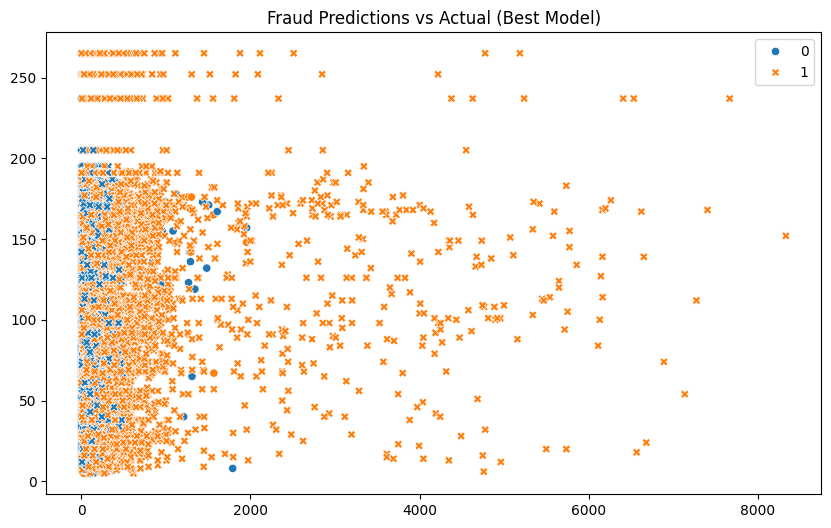

In [71]:
plt.figure(figsize=(10, 6))
sns.scatterplot(x=X_train['amount'].to_numpy(), y=X_train['customer_total_trans'].to_numpy(),
                hue=temp_data['predicted'].to_numpy(), style=y_train.to_numpy())
plt.title("Fraud Predictions vs Actual (Best Model)")
plt.show()

In [74]:
from cuml.cluster import HDBSCAN